In [59]:
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
import numpy as np

In [74]:
def b_to_b(mol, i, j, k):
    b1 = mol.GetBondBetweenAtoms(i,j)
    b2 = mol.GetBondBetweenAtoms(j,k)
    b1_type = int(b1.GetBondTypeAsDouble())
    if b2 is None:
        b2_type = 0
    else:
        b2_type = int(b2.GetBondTypeAsDouble())
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(k)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    e_mol.RemoveBond(i,j)
    e_mol.RemoveBond(j,k)
    if b1_type != 1:
        e_mol.AddBond(i,j, order=Chem.BondType.values[b1_type - 1])
    e_mol.AddBond(j,k, order=Chem.BondType.values[b2_type + 1])
    return e_mol.GetMol()

def a_to_b(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    if not bond:
        e_mol.AddBond(i,j, order=Chem.BondType.values[1])
    else:
        e_mol.RemoveBond(i,j)
        bond_order = int(bond.GetBondTypeAsDouble())
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order+1])
    return e_mol.GetMol()

In [34]:
cw_carbene = Chem.MolFromSmiles("C1O[C]OC1")

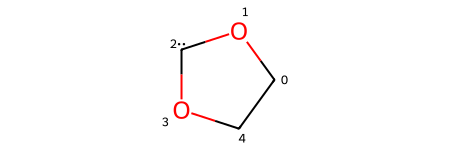

In [35]:
cw_carbene

In [36]:
ir_claisen = Chem.MolFromSmiles("CC(OC([O-])=C)C(C)=C")

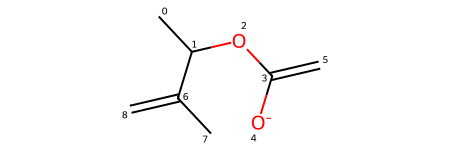

In [37]:
ir_claisen

In [63]:
da = Chem.MolFromSmiles("C1C=CC=C1.C=CC(=O)OCC")

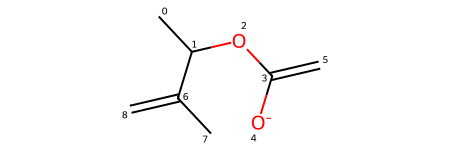

In [70]:
ir_claisen

In [77]:
IPythonConsole.drawOptions.addAtomIndices = True

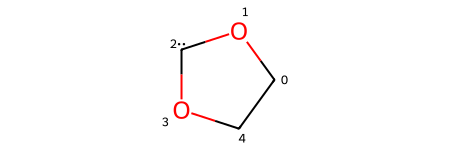

In [87]:
mol = Chem.Mol(cw_carbene)
mol

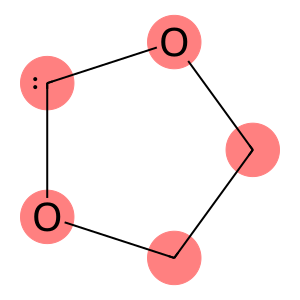

In [88]:
involved_atoms = []
involved_atoms_list = input("Enter the atoms involved in the reaction in order of new connectivity (space separated): ").split()
#involved_atoms_list = [1, 2, 3, 4, 5, 6]

for atom in involved_atoms_list:
    atom = int(atom)
    involved_atoms.append(atom)
Chem.Draw.MolToImage(mol, size=(300, 300), highlightAtoms=involved_atoms)

In [89]:
involved_atoms = np.array(involved_atoms)
len_involved_atoms = len(involved_atoms)
print(list(range(0, len_involved_atoms, 2)))
for idx in range(0, len_involved_atoms -1, 2):
        mol = b_to_b(mol, int(involved_atoms[idx]), int(involved_atoms[idx+1]), int(involved_atoms[(idx+2)%len_involved_atoms]))
if len_involved_atoms % 2 == 0:
        mol = b_to_b(mol, int(involved_atoms[-2]), int(involved_atoms[-1]), int(involved_atoms[0]))
if len_involved_atoms % 2 == 1:
    mol = a_to_b(mol, int(involved_atoms[-1]), int(involved_atoms[0]))


    

[0, 2, 4]


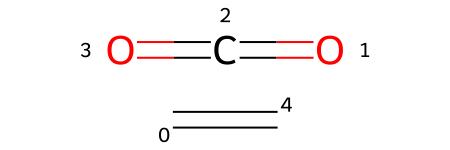

In [91]:
Chem.SanitizeMol(mol)
mol

In [55]:
test = b_to_b(da, 1, 2, 3)
test = b_to_b(test, 3, 4, 5)
test = b_to_b(test, 5, 6, 1)

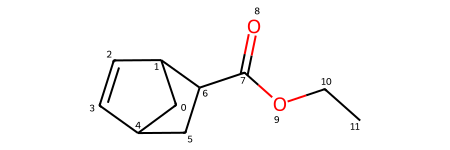

In [40]:
test